### Time Series Data Analysis

- **Dataset Link**: https://www.kaggle.com/datasets/tarunpaparaju/apple-aapl-historical-stock-data

In [36]:
%pip install statsmodels scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [37]:
# Load the dataset
df = pd.read_csv("./datasets/assignment-13.csv")

df.head()

,Date,Close/Last,Volume,Open,High,Low
0,02/28/2020,$273.36,106721200,$257.26,$278.41,$256.37
1,02/27/2020,$273.52,80151380,$281.1,$286,$272.96
2,02/26/2020,$292.65,49678430,$286.53,$297.88,$286.5
3,02/25/2020,$288.08,57668360,$300.95,$302.53,$286.13
4,02/24/2020,$298.18,55548830,$297.26,$304.18,$289.23


In [38]:
# Explore the dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe(include="all"))

print("\nFirst five rows:")
display(df.head())

Dataset shape: (2518, 6)

Column names:
['Date', ' Close/Last', ' Volume', ' Open', ' High', ' Low']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2518 entries, 0 to 2517
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Date         2518 non-null   object
 1    Close/Last  2518 non-null   object
 2    Volume      2518 non-null   int64 
 3    Open        2518 non-null   object
 4    High        2518 non-null   object
 5    Low         2518 non-null   object
dtypes: int64(1), object(5)
memory usage: 118.2+ KB

Missing values:
Date           0
 Close/Last    0
 Volume        0
 Open          0
 High          0
 Low           0
dtype: int64

Statistical summary:


,Date,Close/Last,Volume,Open,High,Low
count,2518,2518,2.518000e+03,2518,2518,2518
unique,2518,2417,NaN,2415,2399,2408
top,03/01/2010,$106.82,NaN,$75,$96.89,$94.1
freq,1,3,NaN,4,3,3
mean,NaN,NaN,7.258009e+07,NaN,NaN,NaN
std,NaN,NaN,5.663113e+07,NaN,NaN,NaN
min,NaN,NaN,1.136205e+07,NaN,NaN,NaN
25%,NaN,NaN,3.053026e+07,NaN,NaN,NaN
50%,NaN,NaN,5.295469e+07,NaN,NaN,NaN
75%,NaN,NaN,9.861006e+07,NaN,NaN,NaN



First five rows:


,Date,Close/Last,Volume,Open,High,Low
0,02/28/2020,$273.36,106721200,$257.26,$278.41,$256.37
1,02/27/2020,$273.52,80151380,$281.1,$286,$272.96
2,02/26/2020,$292.65,49678430,$286.53,$297.88,$286.5
3,02/25/2020,$288.08,57668360,$300.95,$302.53,$286.13
4,02/24/2020,$298.18,55548830,$297.26,$304.18,$289.23


In [39]:
# clean the dataset
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Rename columns for easier coding
df = df.rename(columns={
    "Close/Last": "Close",
    "Close / Last": "Close"
})

# Convert dates to datetime format
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Convert price columns to numeric values
price_columns = ["Close", "Open", "High", "Low"]

for col in price_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(
            "$", "", regex=False).str.replace(",", "", regex=False),
        errors="coerce"
    )

# Convert volume to numeric
df["Volume"] = pd.to_numeric(
    df["Volume"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# Remove rows with missing essential values
df = df.dropna(subset=["Date", "Close", "Volume"])

# Sort dates from oldest to newest
df = df.sort_values("Date").drop_duplicates(subset="Date")

# Use Date as the index
df = df.set_index("Date")

print("Cleaned dataset:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nDate range:", df.index.min(), "to", df.index.max())

Cleaned dataset:


,Close,Volume,Open,High,Low
Date,,,,,
2010-03-01,29.8557,137312041,29.3928,29.9286,29.3500
2010-03-02,29.8357,141486282,29.9900,30.1186,29.6771
2010-03-03,29.9043,92846488,29.8486,29.9814,29.7057
2010-03-04,30.1014,89591907,29.8971,30.1314,29.8043
2010-03-05,31.2786,224647427,30.7057,31.3857,30.6614



Data types:
Close     float64
Volume      int64
Open      float64
High      float64
Low       float64
dtype: object

Date range: 2010-03-01 00:00:00 to 2020-02-28 00:00:00


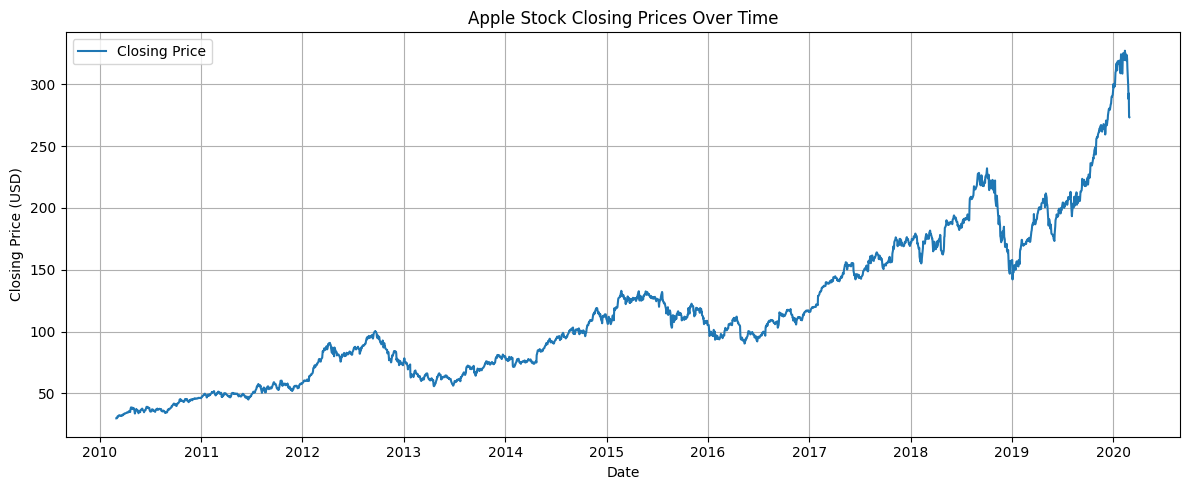

In [40]:
# Plot historical closing prices
plt.figure(figsize=(12, 5))
plt.plot(df.index,df["Close"],label="Closing Price")

plt.title("Apple Stock Closing Prices Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

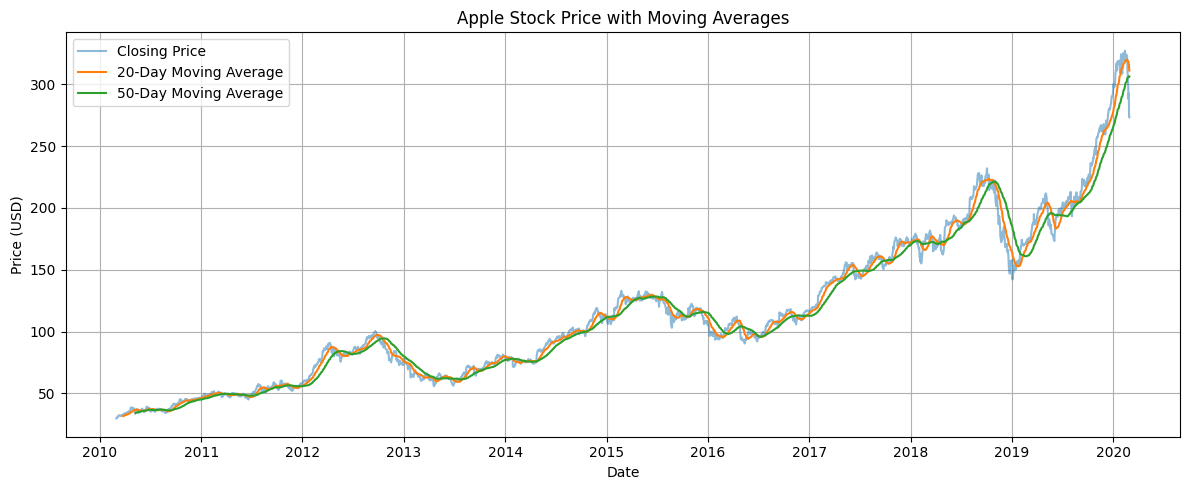

In [41]:
# Calculate and plot moving averages
df["MA20"]=df["Close"].rolling(window=20).mean()
df["MA50"]=df["Close"].rolling(window=50).mean()

plt.figure(figsize=(12, 5))

plt.plot(df.index,df["Close"],label="Closing Price",alpha=0.5)
plt.plot(df.index,df["MA20"],label="20-Day Moving Average")
plt.plot(df.index,df["MA50"],label="50-Day Moving Average")

plt.title("Apple Stock Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

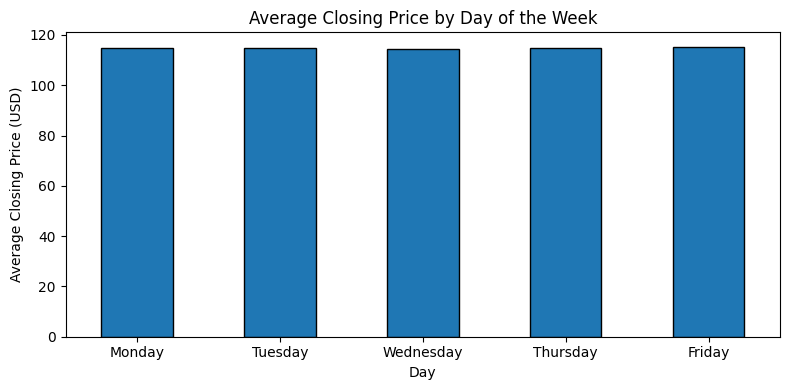

In [42]:
# Analyse seasonality
# A) Avg closing price by day of the week
df["DayOfWeek"] = df.index.day_name()
weekday_order=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekday_prices=(df.groupby("DayOfWeek")["Close"].mean().reindex(weekday_order))
weekday_prices.plot(kind="bar", figsize=(8, 4), edgecolor="black")
plt.title("Average Closing Price by Day of the Week")
plt.xlabel("Day")
plt.xticks(rotation=0)
plt.ylabel("Average Closing Price (USD)")
plt.tight_layout()
plt.show()

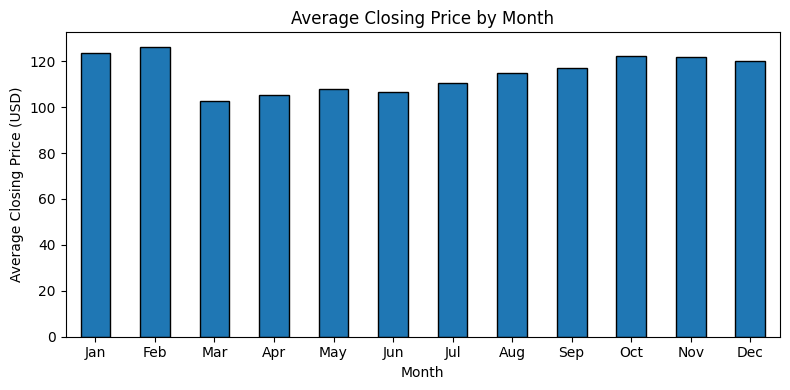

In [43]:
# B.Avg closing price by month
df["Month"]=df.index.month

month_prices=(df.groupby("Month")["Close"].mean())
month_prices.plot(kind="bar", figsize=(8, 4), edgecolor="black")
plt.title("Average Closing Price by Month")
plt.xlabel("Month")
plt.ylabel("Average Closing Price (USD)")
plt.xticks(
    ticks=range(12),
    labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)
plt.tight_layout()
plt.show()

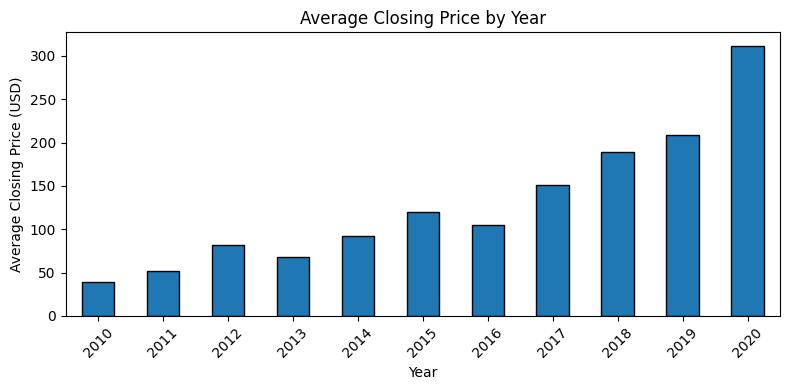

In [44]:
# C.Average closing price by year
df["Year"]=df.index.year
year_prices=(df.groupby("Year")["Close"].mean())
year_prices.plot(kind="bar", figsize=(8, 4), edgecolor="black")
plt.title("Average Closing Price by Year")
plt.xlabel("Year")
plt.xticks(rotation=45)
plt.ylabel("Average Closing Price (USD)")
plt.tight_layout()
plt.show()

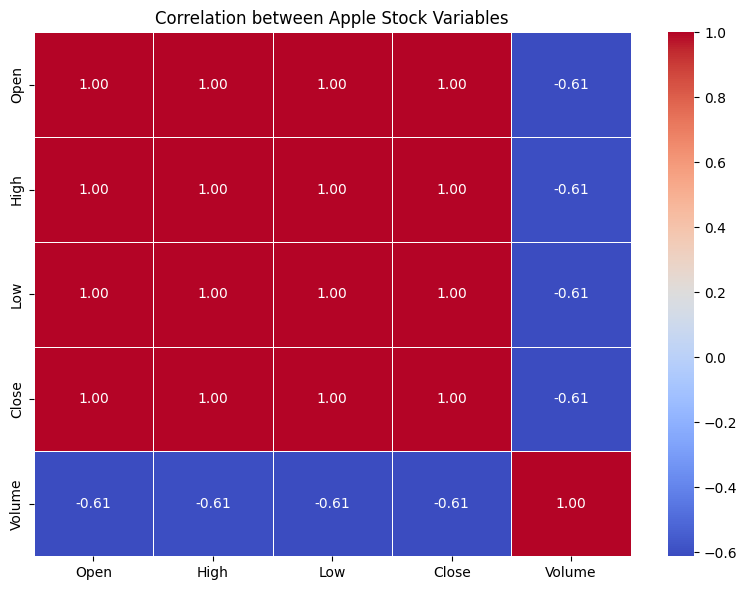

In [45]:
# Coorelation analysis
correlation_data=df[["Open","High","Low","Close","Volume"]]
correlation_matrix=correlation_data.corr()
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidth=0.5
)
plt.title("Correlation between Apple Stock Variables")
plt.tight_layout()
plt.show()

In [46]:
# Prepare data for ARIMA forecasting model
# Use closing price for forecasting
stock_prices=df["Close"].dropna()

split_idx=int(len(stock_prices)*0.8)

train_data=stock_prices[:split_idx].reset_index(drop=True)
test_data=stock_prices[split_idx:].reset_index(drop=True)
print("Training data length:", len(train_data))
print("Test data length:", len(test_data))

Training data length: 2014
Test data length: 504


In [47]:
# Train the ARIMA model
model=ARIMA(train_data,order=(5,1,0))
model_fit=model.fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 2014
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -3588.880
Date:                Wed, 14 Oct 2026   AIC                           7189.761
Time:                        12:15:04   BIC                           7223.405
Sample:                             0   HQIC                          7202.110
                               - 2014                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0358      0.017      2.143      0.032       0.003       0.069
ar.L2         -0.0358      0.018     -1.961      0.050      -0.072   -1.77e-05
ar.L3         -0.0046      0.017     -0.264      0.7

In [48]:
# Forecast the test period and evaluate the model
predictions = model_fit.forecast(steps=len(test_data))
predictions=pd.Series(
    predictions.to_numpy(),
    index=test_data.index
)

# Calculate evaluation metrics
mae=mean_absolute_error(test_data,predictions)
rmse=np.sqrt(mean_squared_error(test_data,predictions))

print("ARIMA Forecast Evaluation")
print("MAE:", round(mae,2))
print("RMSE:", round(rmse,2))

ARIMA Forecast Evaluation
MAE: 36.32
RMSE: 52.15


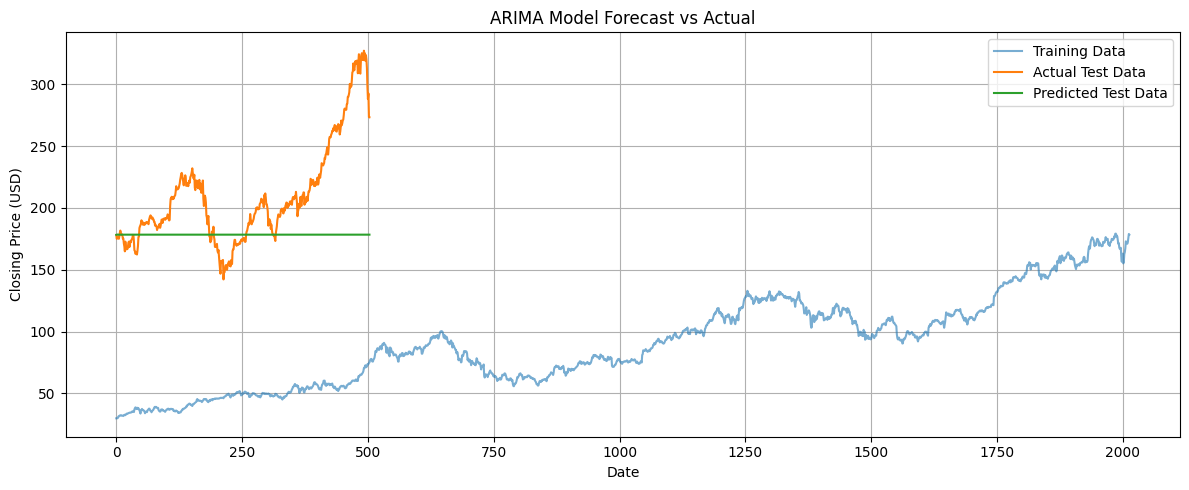

In [49]:
# Plot actual vs predicted values
plt.figure(figsize=(12, 5))

plt.plot(train_data.index,train_data,label="Training Data",alpha=0.6)
plt.plot(test_data.index,test_data,label="Actual Test Data")
plt.plot(predictions.index,predictions,label="Predicted Test Data")


plt.title("ARIMA Model Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### The ARIMA model produced a relatively flat forecast because it relies on patterns in historical stock prices and may not capture sudden market fluctuations or rapid price increases. Stock prices are influenced by many unpredictable factors, making accurate forecasting difficult. The MAE of 36.32 and RMSE of 52.15 indicate that the model's predictions differed considerably from the actual prices. Despite this limitation, the model demonstrates how ARIMA can be applied to time-series forecasting.